In [9]:
!mamba install pandas numpy matplotlib seaborn pingouin scikit-learn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn, pingouin, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 0.886 seconds
  Name                Version               Build                 Channel
---------------------------------------------------------------------------------------
+ brotli-python       1.2.0                 py313h8faef1e_3       emscripten-forge-4x
+ ca-certificates     2026.10.23            hbd8a1cb_0            conda-forge
+ certifi             2026.10.23            pyhd8ed1ab_3          conda-forge
+ charset-normalizer  3.5.1                 pyhd8ed1ab_0          conda-forge
+ idna                3.20                  pyh5ded981_0          conda-forge
+ joblib              1.6.0                 py313h57e9779_0       emscripten-forge-4x
+ littleutils         0.2.4                 pyhd8ed1ab_1          conda-forge
+ mpmath              1.4.1              

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg

nhanes = pd.read_csv(
    "https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/nhanes.csv"
)

children = nhanes[
    nhanes["AgeInYearsAtScreening"] < 18
].copy()

/tmp/xpython_42/1679807800.py:7: DtypeWarning: Columns (141: ServedActiveDutyInUsArmedForces) have mixed types. Specify dtype option on import or set low_memory=False.
  nhanes = pd.read_csv(


In [10]:
children = nhanes[nhanes["AgeInYearsAtScreening"] < 18]

<Axes: >

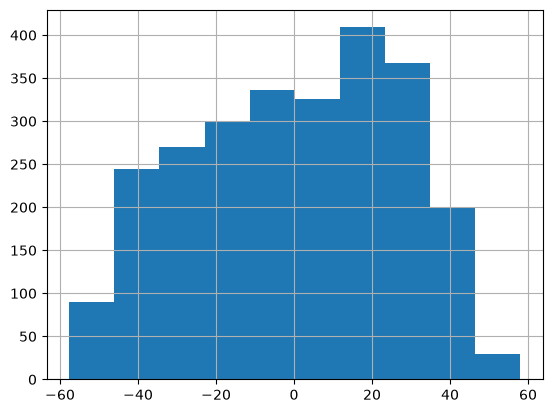

In [11]:
(children["StandingHeightCm"] - children["StandingHeightCm"].mean()).hist()

<Axes: >

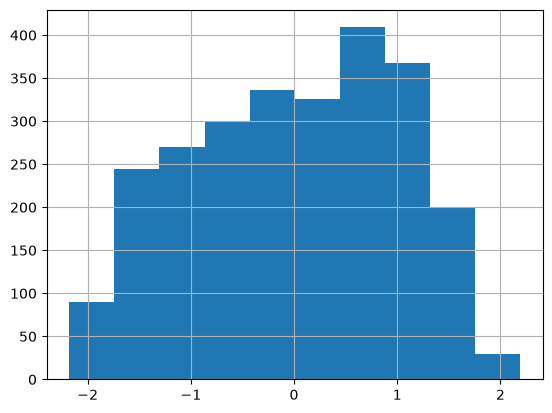

In [19]:
((children["StandingHeightCm"] - children["StandingHeightCm"].mean())/children["StandingHeightCm"].std()).hist()

array([[<Axes: title={'center': 'StandingHeightCm'}>,
        <Axes: title={'center': 'AgeInYearsAtScreening'}>]], dtype=object)

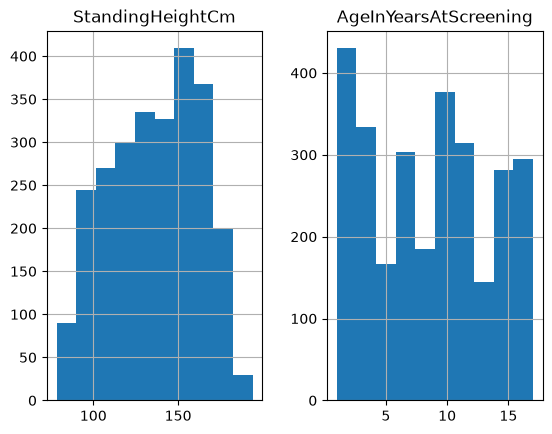

In [20]:
children[["StandingHeightCm","AgeInYearsAtScreening"]].hist()

array([[<Axes: title={'center': 'StandingHeightCm'}>,
        <Axes: title={'center': 'AgeInYearsAtScreening'}>]], dtype=object)

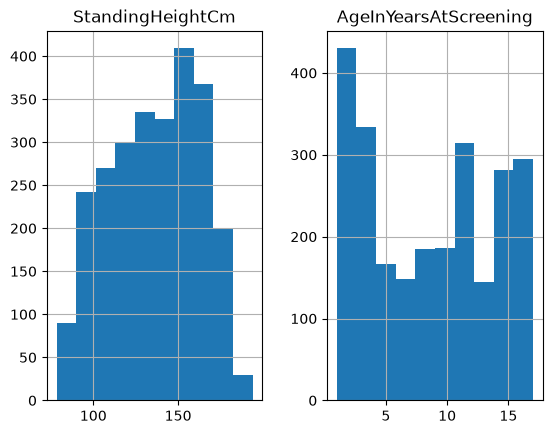

In [21]:
children[["StandingHeightCm","AgeInYearsAtScreening"]].replace([7,9,77,99,777,999,7777,9999], pd.NA).astype("Float64").hist()

In [26]:
children["AgeInYearsAtScreening"].describe()

count    2833.000000
mean        8.513590
std         4.905092
min         1.000000
25%         4.000000
50%         8.000000
75%        13.000000
max        17.000000
Name: AgeInYearsAtScreening, dtype: float64

In [27]:
children["AgeInYearsAtScreening"].dropna().describe()

count    2833.000000
mean        8.513590
std         4.905092
min         1.000000
25%         4.000000
50%         8.000000
75%        13.000000
max        17.000000
Name: AgeInYearsAtScreening, dtype: float64

In [1]:
!pip install seaborn pingouin

mambajs 0.21.4

Process pip requirements ...

Requirement numpy already satisfied.
Cannot install 'pandas' from PyPI because it is a binary built package that is not compatible with WASM environments. To resolve this issue, you can: 1) Try to install it from emscripten-forge instead: "!mamba install pandas" 2) If that doesn't work, it's probably that the package was not made WASM-compatible on emscripten-forge. You can either request or contribute a new recipe for that package in https://github.com/emscripten-forge/recipes 
Requirement matplotlib already satisfied.
Requirement packaging already satisfied.
Cannot install 'scikit-learn' from PyPI because it is a binary built package that is not compatible with WASM environments. To resolve this issue, you can: 1) Try to install it from emscripten-forge instead: "!mamba install scikit-learn" 2) If that doesn't work, it's probably that the package was not made WASM-compatible on emscripten-forge. You can either request or contribute a new 

<Axes: xlabel='StandingHeightCm', ylabel='BodyMassIndexKgm2'>

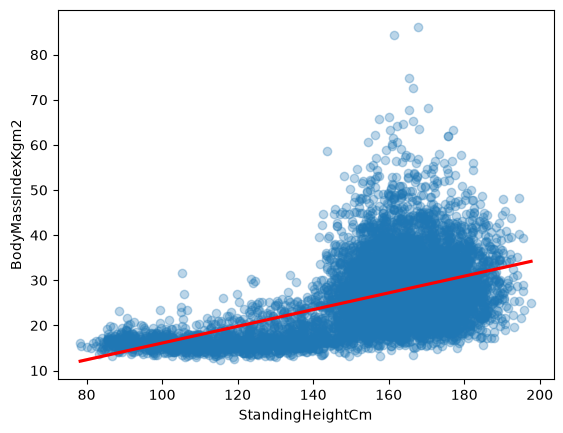

In [13]:
import seaborn as sns
import pingouin as pg
pg.linear_regression(nhanes["StandingHeightCm"], nhanes["BodyMassIndexKgm2"],remove_na=True)
#with vs. without this line:
sns.regplot(data=nhanes,x="StandingHeightCm", y="BodyMassIndexKgm2",scatter_kws={"color": "C0", "alpha": 0.3},line_kws={"color": "red"})

In [12]:
import seaborn as sns
import pingouin as pg
pg.linear_regression(nhanes["StandingHeightCm"], nhanes["BodyMassIndexKgm2"],remove_na=True)
#with vs. without this line:

,names,coef,se,T,pval,r2,adj_r2,CI2.5,CI97.5
0,Intercept,-2.443957,0.568574,-4.298396,0.000017,0.249317,0.249223,-3.558511,-1.329404
1,StandingHeightCm,0.185338,0.003595,51.555402,0.000000,0.249317,0.249223,0.178291,0.192385


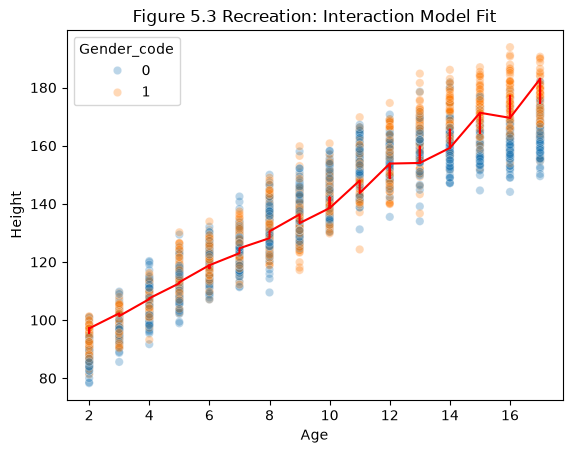

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

# Recode gender and filter non-null children data
children["Gender_code"] = (children["Gender"].astype(str).str.lower().isin(["male", "1"])).astype(int)
children_clean = children[["StandingHeightCm", "AgeInYearsAtScreening", "Gender_code"]].dropna().copy()

# Fit models
m_age = LinearRegression(fit_intercept=False).fit(children_clean[["AgeInYearsAtScreening"]], children_clean["StandingHeightCm"])
m_age_const = LinearRegression().fit(children_clean[["AgeInYearsAtScreening"]], children_clean["StandingHeightCm"])
m_full = LinearRegression().fit(children_clean[["AgeInYearsAtScreening", "Gender_code"]], children_clean["StandingHeightCm"])

children_clean = children_clean.sort_values("AgeInYearsAtScreening")
children_clean["pred_age"] = m_age.predict(children_clean[["AgeInYearsAtScreening"]])
children_clean["pred_age_const"] = m_age_const.predict(children_clean[["AgeInYearsAtScreening"]])
children_clean["pred_full"] = m_full.predict(children_clean[["AgeInYearsAtScreening", "Gender_code"]])

# Interaction term & model
children_clean["Age_Gender"] = (children_clean["AgeInYearsAtScreening"] * children_clean["Gender_code"])
m_interaction = LinearRegression().fit(children_clean[["AgeInYearsAtScreening", "Gender_code", "Age_Gender"]], children_clean["StandingHeightCm"])
children_clean["pred_interaction"] = m_interaction.predict(children_clean[["AgeInYearsAtScreening", "Gender_code", "Age_Gender"]])

# Display fitted sample graph
sns.scatterplot(data=children_clean, x="AgeInYearsAtScreening", y="StandingHeightCm", hue="Gender_code", alpha=0.3)
plt.plot(children_clean["AgeInYearsAtScreening"], children_clean["pred_interaction"], color="red", label="Interaction Fit")
plt.title("Figure 5.3 Recreation: Interaction Model Fit")
plt.xlabel("Age")
plt.ylabel("Height")
plt.show()